In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
os.chdir(os.path.abspath('..'))

In [2]:
import pandas as pd
import re
import json
import ast
from os import fdopen, remove
from tempfile import mkstemp
from shutil import move, copymode
from pprint import pprint 
from io import StringIO
import os
import string
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

import spacy
from spacy.language import Language
from spacy_language_detection import LanguageDetector
nlp = spacy.load('de_core_news_lg')

from utils.tfidf_utils import remove_punctuation, remove_stop_words_from_text, calc_tf_idf

def flatten(xss):
    return [x for xs in xss for x in xs]

leipzig_years_path = "generated_data/Leipzig_sentences_all_year_counts.csv"
plots_dir = "plots/"

In [2]:
try:
    with open('corpus_texts/taz24_year_counts.json', 'r', encoding='utf-8') as f:
            meta_years = json.load(f)
    print("Metayears loaded successfully.", meta_years.keys())
except FileNotFoundError:
    raise FileNotFoundError("metadata file not found")

Metayears loaded successfully. dict_keys(['2013', '2014', '2022', '2024', '2023', '2015', '2012', '1988', '1986', '1987', '1980', '1989', '1993', '1994', '1995', '1992', '2008', '2001', '2006', '2007', '2000', '2009', '2017', '2010', '2019', '2021', '2020', '2018', '2011', '2016', '1985', '1983', '1984', '1997', '1990', '1999', '1998', '1991', '1996', '2005', '2002', '2003', '2004'])


In [3]:
try:
    with open('corpus_texts/taz24_metadata.json', 'r', encoding='utf-8') as f:
            meta = json.load(f)
    print("Metadata loaded successfully.", meta.keys())
except FileNotFoundError:
    raise FileNotFoundError("metadata file not found")

Metadata loaded successfully. dict_keys(['501045', '501051', '501053', '501055', '501056', '501058', '501062', '501064', '501065', '501079', '501081', '501096', '501098', '501102', '501105', '501108', '501111', '501114', '501118', '501121', '501123', '501127', '501130', '501131', '501133', '501134', '501136', '501143', '501148', '501150', '501152', '501154', '501156', '501158', '501161', '501166', '501170', '501172', '501174', '501182', '501185', '501188', '501193', '501199', '501210', '501213', '501215', '501221', '501223', '501225', '501227', '501229', '501233', '501235', '501239', '501240', '501242', '501244', '501245', '501268', '501270', '501271', '501272', '501273', '501274', '501277', '501279', '501281', '501282', '501283', '501284', '501285', '501286', '501287', '501288', '501290', '501291', '501292', '501293', '501294', '501295', '501296', '501297', '501299', '501300', '501301', '501302', '501303', '501304', '501305', '501306', '501307', '501309', '501310', '501311', '501312',

### Daten veranschaulichen:
- Häufigkeit der KI Terme
- Häufigste Wörter
- TF-IDF Wörter Veranschaulichen
- length of sentences / number of clauses
- number / type of verbs
- number / type of adjektives

In [4]:
docs_ki = pd.read_csv(StringIO(open('generated_data/KI_sentences_tfidf_translated.csv').read()))
print("KI sentences loaded successfully.", docs_ki.columns)

ki_docs = docs_ki[docs_ki['original'].isna() == False].reset_index()
non_ki_docs = docs_ki[docs_ki['original'].isna() == True].reset_index()

print(f"Number of KI docs: {len(ki_docs)}")
print(f"Number of other docs: {len(non_ki_docs)}")
non_ki_docs.head()

KI sentences loaded successfully. Index(['id', 'original', 'translation'], dtype='str')
Number of KI docs: 572
Number of other docs: 0


,index,id,original,translation


In [5]:
docs_ai = pd.read_json(StringIO(open('generated_data/AI_sentences/AI_sentences_tfidf.json').read()), orient="index")

ai_docs = docs_ai[docs_ai['sentences'].isna() == False].reset_index()
non_ai_docs = docs_ai[docs_ai['sentences'].isna() == True].reset_index()

print(f"Number of AI docs: {len(ai_docs)}")
print(f"Number of other docs: {len(non_ai_docs)}")
docs_ai.head()

Number of AI docs: 0
Number of other docs: 574


,sentences,top_words
5315432.txt,NaN,"['scooter 25', 'scooter', 'pushes scooter', 'p..."
5124643.txt,NaN,"['unarmed civilians', 'government forces', 'ba..."
5094180.txt,NaN,"['weiwei does', 'weiwei', 'shortcoming', 'nomi..."
851887.txt,NaN,"['philipp palm', 'philipp', 'palm crisis', 'pa..."
5455271.txt,NaN,"['world 2000', 'world', 'ki', '2000 ki', '2000']"


In [6]:
# filtered Ki sentences with regex
docs_sents = pd.read_csv(StringIO(open('generated_data/AI_sentences/KI_sentences_translated.csv').read()))
docs_full = pd.read_csv(StringIO(open('generated_data/AI_sentences/KI_sentences_full_translated.csv').read()))

with open("generated_data/AI_sentences/Leipzig_KI_sentences_all.json", "r") as f:
    docs_leipzig = json.load(f)

print(f"Number of docs_full: {len(docs_full)}")
print(f"Number of docs_sents: {len(docs_sents)}")
docs_sents.head()

Number of docs_full: 2
Number of docs_sents: 75


,id,original,translation
0,851887.txt,"[""taz herr palm man liest von gewalt an ihrer ...","[""philipp palm it is not that we are in a seri..."
1,5322249.txt,"[""druck auf palm recyclingpapier""]","[""printing on palm recycled paper""]"
2,5903441.txt,"[""palm recyclingpapier a beig""]","[""palm recycled paper a beig""]"
3,5318710.txt,"[""neben palm und ölzweig den symbolen für frie...","[""next to palm and olive branch the symbols fo..."
4,0240207.txt,"[""weltweit 2230 west art 2315 irina palm""]","[""worldwide 2230 west art 2315 irina palm""]"


In [7]:
stopwords = open("config_files/spacy_stopwords.txt").read().replace("{", '[').replace("}",']')
stopwords = ast.literal_eval(stopwords)

In [8]:
def sents_per_year(df, meta):
    df_res = pd.DataFrame(df).copy()
    year_col = []
    # Map ids in dataframe to years using metadata; fall back to extracting year from id if present
    for id_df in df["id"]:
        id_str = re.sub(r'\.\w+$', '', id_df).replace('_full', '')  # remove file extension and underscores
        if id_str not in meta:
            print(f"Warning: id {id_df, id_str} not found in metadata")
        else:
            meta_year = meta[id_str].get("published_on")
            year = re.match(r'(\d{4})', meta_year).group(1)
            if year is None:
                print(f"Warning: published_on missing for id {id_df, id_str} in metadata")
                year_col.append("0000")
            else:
                year_col.append(year)
    df_res['year'] = year_col    
    return df_res

# Häufigste Wörter pro jahr 
def top_words_year(df):
    try:
        with open('corpus_texts/taz24_metadata.json', 'r', encoding='utf-8') as f:
            meta = json.load(f)
    except FileNotFoundError:
        raise FileNotFoundError("metadata file not found")

    df_res = pd.DataFrame(df).copy()
    year_col = []
    # Map ids in dataframe to years using metadata; fall back to extracting year from id if present
    for id_df in df["id"]:
        id_str = re.sub(r'\.\w+$', '', id_df).replace('_full', '')  # remove file extension and underscores
        if id_str not in meta:
            print(f"Warning: id {id_df, id_str} not found in metadata")
        else:
            meta_year = meta[id_str].get("published_on")
            year = re.match(r'(\d{4})', meta_year).group(1)
            if year is None:
                print(f"Warning: published_on missing for id {id_df, id_str} in metadata")
                year_col.append("0000")
            else:
                year_col.append(year)
    df_res['year'] = year_col
    df_res.to_csv("generated_data/KI_sentences_years.csv", index=False)
    
    return df_res


def get_POS(token_list):
    return [token.pos_ for token in token_list]

# helper to obtain tokens from an element
def tokens_from_item(item, nlp):
    # spaCy Token lists / Docs / Spans 
    if hasattr(item, "pos_") or (hasattr(item, "__iter__") and not isinstance(item, str) and len(item) and hasattr(item[0], "pos_")):
        # item is a Token, Doc, Span, or list of Tokens
        return list(item)
    return list(nlp(str(item)))

# Count top words by POS tag (supports token lists, spaCy Docs/Spans, or raw text)
def get_top_POS(df_col, pos, k):
    # detect whether we need to load a model (when any element is a string)
    try:
        # df_col can be a pandas Series
        iterable = df_col
        if hasattr(df_col, "dropna"):
            iterable = df_col.dropna().values
    except Exception:
        iterable = df_col

    counts = Counter()
    for item in iterable:
        tokens = _tokens_from_item(item, nlp)
        for token in tokens:
            # ensure token has pos_ and is alphabetic
            if getattr(token, "pos_", None) == pos and getattr(token, "is_alpha", False):
                lemma = getattr(token, "lemma_", token.text).lower()
                counts[lemma] += 1

    top_k = pd.Series(dict(counts.most_common(k)))
    print(f"\n{k} most frequent {pos}:\n", top_k)
    # save to file
    top_k.to_csv(f'generated_data/{pos}_{df_col}')
    return top_k

In [9]:
# Häufigste Wörter insgesamt
def top_words(df_col, k):
    top_k = df_col.str.split().apply(lambda x: pd.Series(remove_stop_words_from_text(x, stopwords))).stack().value_counts().head(k)
    print(f"\n{k} most frequent words:\n", top_k)
    return top_k

# Häufigste Wörter pro jahr 
def top_words_per_year(df, k): 
    top_k_year = df.groupby('year')['text'].apply(lambda x: x.str.split().apply(lambda y: pd.Series(y)).stack().value_counts().head(k))
    print(f"\n{k} most frequent words per year:\n", top_k_year)
    return top_k_year

#### TFIDF of KI_sentences filtered with regex

In [10]:
# compare KI_sentences and KI_sentences_full ids
ids_full = [x.replace("_full", "") for x in docs_full["id"].tolist()]
all_ids = docs_sents["id"].tolist() + ids_full
set_all_ids = set(all_ids)
set_all_og_ids = set(docs_sents["id"].tolist() + docs_full["id"].tolist())
non_repeated_ids = [x for x in set_all_ids if x not in ids_full] + [x for x in ids_full if x not in set_all_ids]
print(f"Number of ids: {len(all_ids)}, len unique ids: {len(set_all_ids)}, len non-repeated ids: {len(non_repeated_ids)}")
print("Non-repeated ids:", str(non_repeated_ids))
print("all original ids:", str(set_all_og_ids))

# combine all entries for non_repeated_ids into a df
all_ai_df = pd.concat([
    docs_sents[docs_sents['id'].isin(non_repeated_ids)],
    docs_full[docs_full['id'].str.replace('_full', '').isin(non_repeated_ids)]
    ], ignore_index=True).drop_duplicates(subset=['id'], keep='first')
# calc tfidf on result
all_ai_texts = all_ai_df['original'].tolist()
all_ai_keywords = calc_tf_idf(all_ai_texts)
tfidf_ai = calc_tf_idf(all_ai_texts, stopwords)
# save tfidf results to file
with open('generated_data/All_AI_sentences_tfidf.txt', 'w', encoding='utf-8') as f:
    for keyword in all_ai_keywords:
        f.write(f"{keyword}\n")


Number of ids: 77, len unique ids: 75, len non-repeated ids: 73
Non-repeated ids: ['5907912.txt', '5909029.txt', '1825921.txt', '851884.txt', '1902527.txt', '810137.txt', '5911712.txt', '810954.txt', '1825920.txt', '5318642.txt', '479671.txt', '5124622.txt', '1736262.txt', '1247624.txt', '489557.txt', '1569401.txt', '1923030.txt', '1865855.txt', '0242576.txt', '5908259.txt', '5909055.txt', '5902471.txt', '1646855.txt', '1855481.txt', '5320721.txt', '5148089.txt', '0409858.txt', '5906272.txt', '854829.txt', '480385.txt', '1248965.txt', '0399973.txt', '5905841.txt', '853901.txt', '5908323.txt', '1917593.txt', '5829220.txt', '5167938.txt', '1181418.txt', '0240207.txt', '1649494.txt', '806067.txt', '5322249.txt', '0236072.txt', '0242523.txt', '1608779.txt', '5903441.txt', '0239343.txt', '5023597.txt', '1249570.txt', '1248233.txt', '1917552.txt', '1737898.txt', '5453459.txt', '654816.txt', '1183035.txt', '1365278.txt', '0316205.txt', '851887.txt', '5905296.txt', '5318710.txt', '5493788.txt'

#### KI_sentence stats

/var/folders/0h/lr036jk55nq7b5pmf0kg0qq40000gn/T/ipykernel_23920/253733557.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(years, rotation=45, size=15)


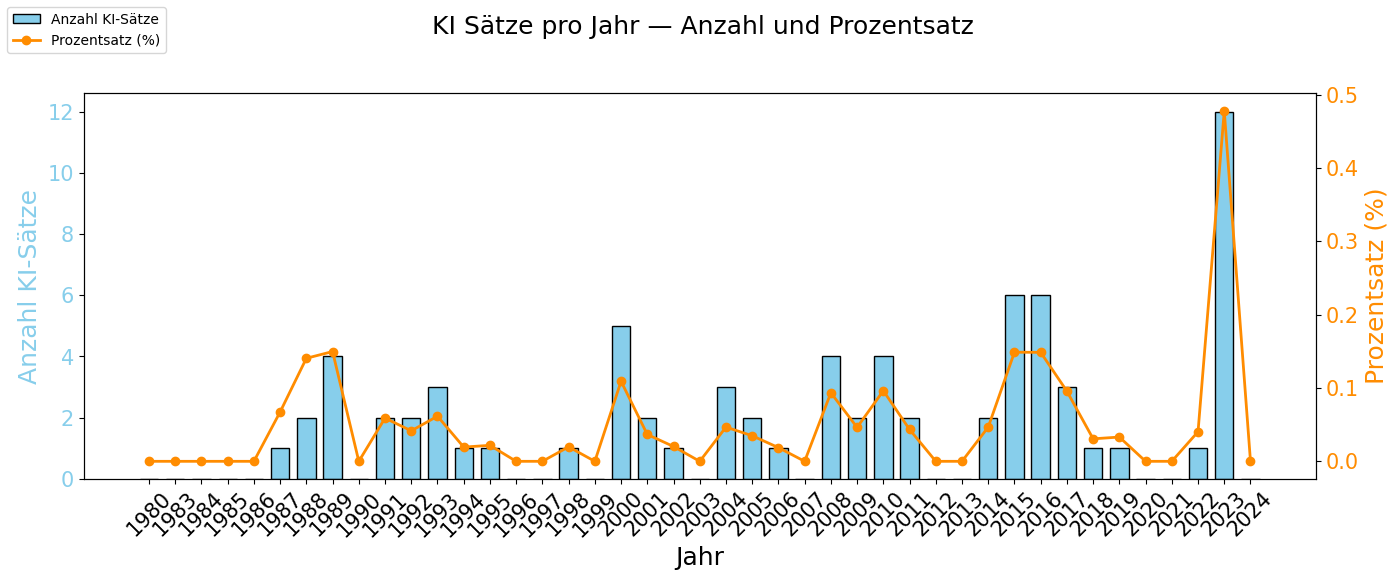

<Figure size 640x480 with 0 Axes>

In [11]:
# exclude unknown years ('0000') and aggregate counts
sents_by_year = sents_per_year(docs_sents, meta)
sents_years = pd.Series(sents_by_year['year'])
sents_years = sents_years[sents_years != '0000'].value_counts().sort_index()
sents_by_year.to_csv("corpus_texts//KI_sentences_years.csv", index=False)
# get total (non ai + ai) counts
year_total_counts = pd.Series(meta_years).sort_index()
years = sorted(set(list(sents_years.keys()) + list(year_total_counts.keys())))
counts = [sents_years.get(y, 0) for y in years]
totals = [year_total_counts.get(y, 0) for y in years]
percentages = [100 * (c / t) if t > 0 else 0 for c, t in zip(counts, totals)]

#plot
fig, ax1 = plt.subplots(figsize=(14, 6))
ax1.bar(years, counts, color='skyblue', edgecolor='black', label='Anzahl KI-Sätze', width=0.7)
ax1.set_xlabel('Jahr', fontsize=18)
ax1.set_ylabel('Anzahl KI-Sätze', color='skyblue', fontsize=18)
ax1.tick_params(axis='y', labelcolor='skyblue', labelsize=15)
ax1.set_xticklabels(years, rotation=45, size=15)

ax2 = ax1.twinx()
ax2.plot(years, percentages, color='darkorange', marker='o', linewidth=2, label='Prozentsatz (%)')
ax2.set_ylabel('Prozentsatz (%)', color='darkorange', fontsize=18)
ax2.tick_params(axis='y', labelcolor='darkorange', labelsize=15)

fig.suptitle('KI Sätze pro Jahr — Anzahl und Prozentsatz', fontsize=18)
fig.tight_layout(rect=[0, 0.03, 1, 0.95])
# combined legend
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
fig.legend(lines + lines2, labels + labels2, loc='upper left')
plt.show()
# Save figure
plt.savefig(plots_dir + 'KI_sentences_per_year.png')

In [12]:
sents_by_year_l = pd.read_csv("generated_data/Leipzig_sentences_all_year_counts.csv", sep="\t", names=["year", "count"])
sents_by_year_l['year'] = sents_by_year_l['year'].astype(str).str.replace(r'(_.*)$', '', regex=True)
sents_by_year_l['year'] = pd.to_numeric(sents_by_year_l['year'].str.extract(r'(\d{4})')[0], errors='coerce').astype(int)
sents_by_year_l = sents_by_year_l.groupby('year', as_index=False)['count'].sum().sort_values('year')
print(len(sents_by_year_l))

31


In [13]:
leipzig_by_year = pd.read_csv("generated_data/Leipzig_KI_sentences_all_counts.csv", sep="\t", names=["year", "count"])
leipzig_by_year['year'] = leipzig_by_year['year'].astype(str).str.replace(r'(_.*)$', '', regex=True)
leipzig_by_year['year'] = pd.to_numeric(leipzig_by_year['year'].str.extract(r'(\d{4})')[0], errors='coerce').astype(int)
# aggregate duplicate year entries by summing their counts
leipzig_by_year = leipzig_by_year.groupby('year', as_index=False)['count'].sum().sort_values('year')
print(len(leipzig_by_year))

31


max percentage: 0.3357 
in year: 2025 with count: 3357 and total: 1000000


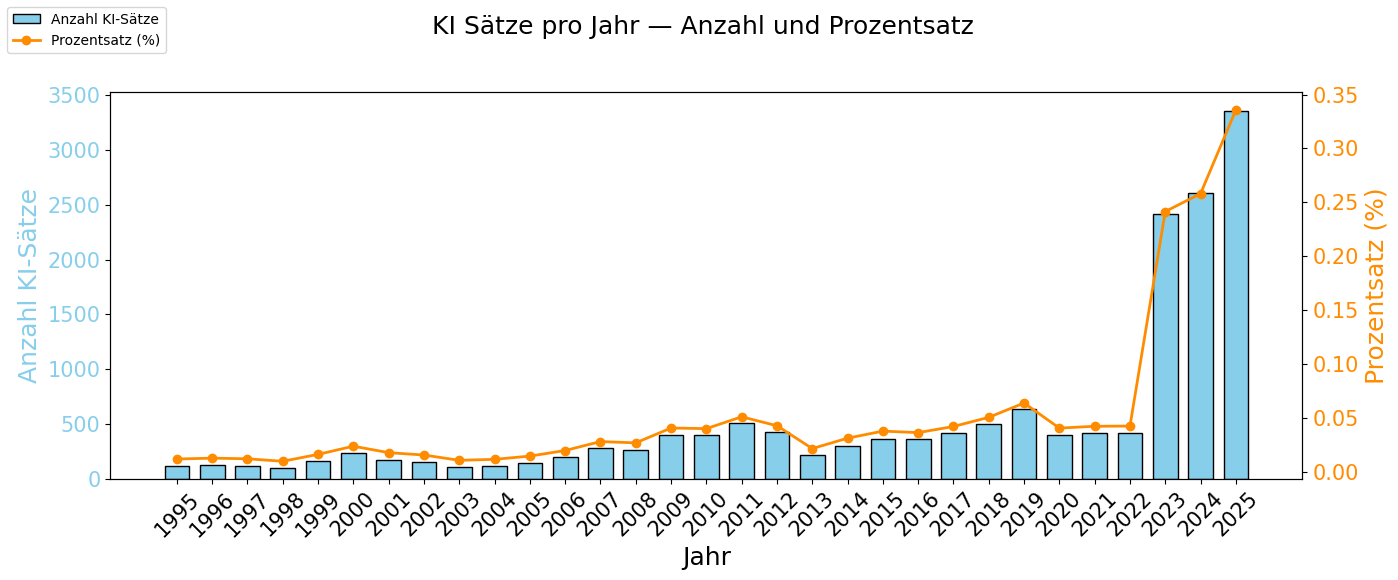

<Figure size 640x480 with 0 Axes>

In [14]:
# Plot Leipzig docs with id mapped to year

# percentages of ai docs per year
# number of sentences per year — compute and plot
years_l = sorted(set(list(leipzig_by_year["year"]) + list(sents_by_year_l["year"])))
counts_l = leipzig_by_year["count"].to_list()
#totals = [sents_by_year_l[sents_by_year_l["year"] == y]["count"].iloc[0] if not sents_by_year_l[sents_by_year_l["year"] == y].empty else 0 for y in years]
totals_l = sents_by_year_l["count"].to_list()
percentages_l = [100 * (c / t) if t > 0 else 0 for c, t in zip(counts_l, totals_l)]
print("max percentage:", max(percentages_l), "\nin year:", years_l[percentages_l.index(max(percentages_l))], "with count:", counts_l[percentages_l.index(max(percentages_l))], "and total:", totals_l[percentages_l.index(max(percentages_l))])

#plot
fig, ax1 = plt.subplots(figsize=(14, 6))
ax1.bar(years_l, counts_l, color='skyblue', edgecolor='black', label='Anzahl KI-Sätze', width=0.7)
ax1.set_xticks(years_l)
ax1.set_xlabel('Jahr', fontsize=18)
ax1.set_ylabel('Anzahl KI-Sätze', color='skyblue', fontsize=18)
ax1.tick_params(axis='y', labelcolor='skyblue', labelsize=15)
ax1.set_xticklabels(years_l, rotation=45, size=15)

ax2 = ax1.twinx()
ax2.plot(years_l, percentages_l, color='darkorange', marker='o', linewidth=2, label='Prozentsatz (%)')
ax2.set_ylabel('Prozentsatz (%)', color='darkorange', fontsize=18)
ax2.tick_params(axis='y', labelcolor='darkorange', labelsize=15)

fig.suptitle('KI Sätze pro Jahr — Anzahl und Prozentsatz', fontsize=18)
fig.tight_layout(rect=[0, 0.03, 1, 0.95])
# combined legend
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
fig.legend(lines + lines2, labels + labels2, loc='upper left')
plt.show()
# Save figure
plt.savefig(os.path.join(plots_dir, 'Leipzig_docs_per_year.png'))

max percentage: 0.3357 
in year: 2025 with count: 3357 and total: 1000000


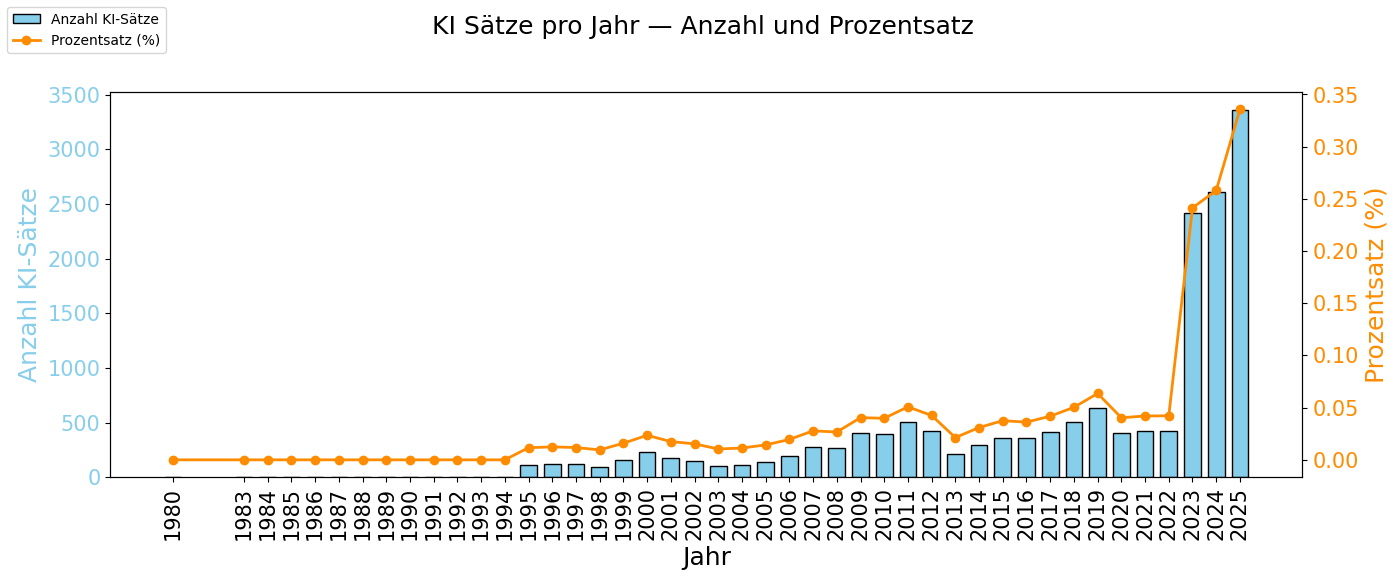

<Figure size 640x480 with 0 Axes>

In [15]:
# Häufigkeit und % der einzelnen KI Terme für beide datensätze

years = [int(x) for x in years]
counts = [sents_years.get(y, 0) for y in years]
totals = [year_total_counts.get(y, 0) for y in years]
percentages = [100 * (c / t) if t > 0 else 0 for c, t in zip(counts, totals)]

# percentages of ai docs per year
# number of sentences per year — compute and plot
# combine year lists and align counts/totals
years_t = sorted(set(years + years_l))
leipzig_map = dict(zip(leipzig_by_year['year'].astype(int).tolist(), leipzig_by_year['count'].tolist()))
sents_map = dict(zip(sents_by_year_l['year'].astype(int).tolist(), sents_by_year_l['count'].tolist()))
counts_t = [leipzig_map.get(y, 0) for y in years_t]
totals_t = [sents_map.get(y, 0) for y in years_t]
percentages_t = [100 * (c / t) if t > 0 else 0 for c, t in zip(counts_t, totals_t)]
print("max percentage:", max(percentages_t), "\nin year:", years_t[percentages_t.index(max(percentages_t))], "with count:", counts_t[percentages_t.index(max(percentages_t))], "and total:", totals_t[percentages_t.index(max(percentages_t))])

#plot
fig, ax1 = plt.subplots(figsize=(14, 6))
ax1.bar(years_t, counts_t, color='skyblue', edgecolor='black', label='Anzahl KI-Sätze', width=0.7)
ax1.set_xticks(years_t)
ax1.set_xlabel('Jahr', fontsize=18)
ax1.set_ylabel('Anzahl KI-Sätze', color='skyblue', fontsize=18)
ax1.tick_params(axis='y', labelcolor='skyblue', labelsize=15)
ax1.set_xticklabels(years_t, rotation=90, size=15)

ax2 = ax1.twinx()
ax2.plot(years_t, percentages_t, color='darkorange', marker='o', linewidth=2, label='Prozentsatz (%)')
ax2.set_ylabel('Prozentsatz (%)', color='darkorange', fontsize=18)
ax2.tick_params(axis='y', labelcolor='darkorange', labelsize=15)

fig.suptitle('KI Sätze pro Jahr — Anzahl und Prozentsatz', fontsize=18)
fig.tight_layout(rect=[0, 0.03, 1, 0.95])
# combined legend
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
fig.legend(lines + lines2, labels + labels2, loc='upper left')
plt.show()
# Save figure
plt.savefig(os.path.join(plots_dir, 'All_ai_docs_per_year.png'))


In [16]:
# number and type of verbs using tokens_from_item()
def count_POS(df_col, nlp, pos_tag): # Verb, ADJ, etc.
    tag_count = 0
    tag_types = Counter()
    for text in df_col:
        if len(text)>1:
            tokens = tokens_from_item(text, nlp)
            #print(text,tokens)
            for token in tokens:
                if token.pos_ == pos_tag:
                    tag_count += 1
                    tag_types[token.lemma_] += 1
    print(f"Total {pos_tag}s: {tag_count}")
    print(f"{pos_tag} types:")
    for tag, count in tag_types.most_common():
        print(f"  {tag}: {count}")
    # plot top 20 types
    top_tags = tag_types.most_common(20)
    tags, counts = zip(*top_tags)
    plt.figure(figsize=(10,5))
    plt.bar(tags, counts,color='skyblue')
    plt.title(f'Top {pos_tag}', fontsize=15)
    plt.xlabel(f'{pos_tag} Lemma', fontsize=15)
    #plt.ylabel('Anzahl', fontsize = 18)
    plt.xticks(rotation=90, size=15)
    plt.yticks(size=15)
    plt.tight_layout()
    plt.show()
    plt.savefig(os.path.join(plots_dir, f'top_{pos_tag}_types.png')) 



In [17]:
# docs_sents already a DataFrame with columns ['id','original','translation']
# docs_leipzig was loaded from json – it may be a dict or a list of dicts

# turn the Leipzig object into a DataFrame with columns id/text
if isinstance(docs_leipzig, dict):
    leipzig_df = pd.DataFrame([{'id': k, 'text': v} for k, v in docs_leipzig.items()])
    # turn the Leipzig object into a DataFrame with columns id/text
    if isinstance(docs_leipzig, dict):
        leipzig_df = pd.DataFrame([{'id': k, 'text': v} for k, v in docs_leipzig.items()])
        l_df = pd.DataFrame(columns=['id', 'text'])
        for item in leipzig_df['text']:
            if isinstance(item, dict):
                tmp_df = pd.DataFrame({'id': list(item.keys()), 'text': list(item.values())})
                l_df = pd.concat([l_df, tmp_df], ignore_index=True)
            else:
                print('not a dict')

# pick the translation field from the taz sentences as the text
sents_df = docs_sents[['id','original']].rename(columns={'original':'text'})
all_sents_df = pd.concat([sents_df, l_df], ignore_index=True)

pprint(all_sents_df)

                id                                               text
0       851887.txt  ["taz herr palm man liest von gewalt an ihrer ...
1      5322249.txt                 ["druck auf palm recyclingpapier"]
2      5903441.txt                    ["palm recyclingpapier a beig"]
3      5318710.txt  ["neben palm und ölzweig den symbolen für frie...
4      0240207.txt         ["weltweit 2230 west art 2315 irina palm"]
...            ...                                                ...
16493       996008  zwar ist ki seit mitte des letzten jahrhundert...
16494       996460  zwar verbessern sich llms mit jeder neuen vers...
16495       997251  zwei forscher des army research laboratory dem...
16496       998513  zweitens genügt die künstliche intelligenz qua...
16497       998530  zweitens ki ist vielleicht ein gewaltiger sege...

[16498 rows x 2 columns]


In [ ]:
# count verbs in all sentences
count_POS(all_sents_df['text'], nlp, 'VERB')

Total ADJs: 21465
ADJ types:
  künstlich: 3145
  neu: 935
  groß: 479
  erster: 318
  anderer: 286
  eigen: 246
  deutsch: 240
  weit: 217
  gut: 216
  chinesisch: 186
  digital: 175
  menschlich: 151
  hoch: 143
  vergangen: 140
  wichtig: 131
  generativ: 128
  aktuell: 121
  nächster: 119
  letzter: 115
  Unogeneralsekretär: 113
  Audi: 113
  jung: 105
  europäisch: 102
  klein: 99
  international: 96
  zweiter: 96
  verschieden: 95
  sogenannter: 82
  zahlreich: 77
  ganz: 76
  alt: 73
  technisch: 67
  französisch: 66
  bestimmt: 65
  kommend: 64
  modern: 61
  stark: 60
  möglich: 58
  führend: 58
  komplex: 58
  echt: 58
  früh: 56
  lang: 55
  vereint: 53
  dritter: 53
  amerikanisch: 53
  politisch: 51
  bekannt: 49
  schnell: 48
  zentral: 47
  global: 46
  richtig: 45
  entsprechend: 45
  Berliner: 44
  einzig: 44
  klassisch: 43
  intelligent: 43
  breit: 42
  kurz: 42
  sozial: 42
  mobil: 41
  ehemalig: 41
  künftig: 39
  entwickelt: 39
  konkret: 38
  weltweit: 38
  best

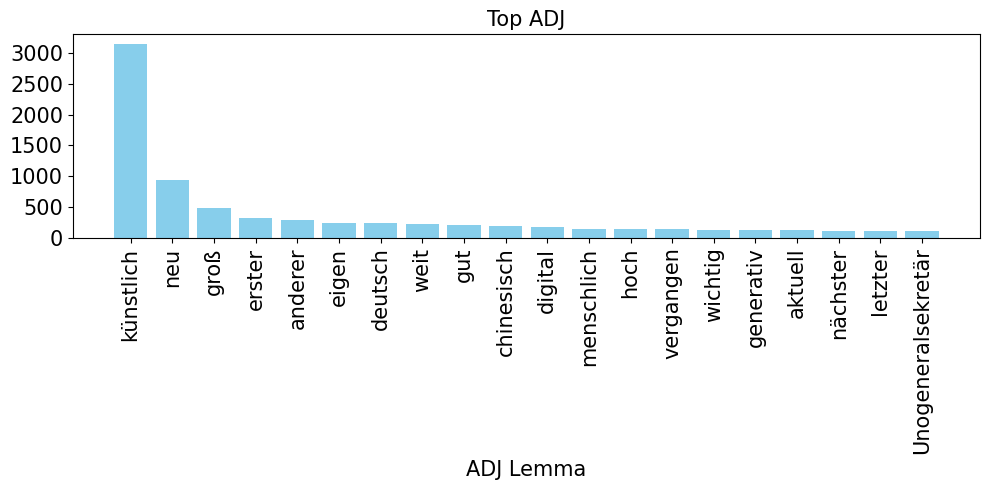

<Figure size 640x480 with 0 Axes>

In [ ]:
# count adjectives in all sentences
count_POS(all_sents_df['text'], nlp, 'ADJ')

Total PROPNs: 34043
PROPN types:
  ki: 5386
  ai: 2282
  Palm: 1630
  Chatgpt: 1153
  Moon: 772
  Gemini: 384
  Beach: 351
  Google: 348
  ban: 283
  weiwei: 243
  international: 216
  Microsoft: 214
  amnesty: 212
  Deutschland: 190
  lms: 168
  New: 156
  Weiwei: 152
  USA: 146
  York: 146
  China: 135
  open: 126
  Pre: 119
  Ki: 116
  Springs: 110
  Berlin: 107
  Meta: 107
  cap: 104
  Apple: 103
  Transformer: 98
  openai: 95
  Europa: 94
  gpt: 89
  Florida: 87
  dpa: 84
  r8: 75
  --: 70
  EU: 66
  intelligence: 65
  Cloud: 65
  Andreas: 62
  Pilot: 59
  West: 55
  Trump: 54
  Data: 53
  Intelligence: 51
  pad: 48
  of: 47
  München: 47
  Windows: 47
  Peking: 47
  Audi: 45
  Llama: 44
  Musk: 44
  act: 41
  Altman: 41
  Nvidia: 41
  Samsung: 40
  moon: 40
  Artificial: 39
  Ultra: 38
  Österreich: 38
  asus: 37
  Michael: 36
  Donald: 36
  Facebook: 35
  County: 35
  llm: 35
  Sam: 35
  Sugiyama: 34
  and: 34
  Webos: 34
  Christian: 33
  Frankreich: 33
  for: 33
  Generativer:

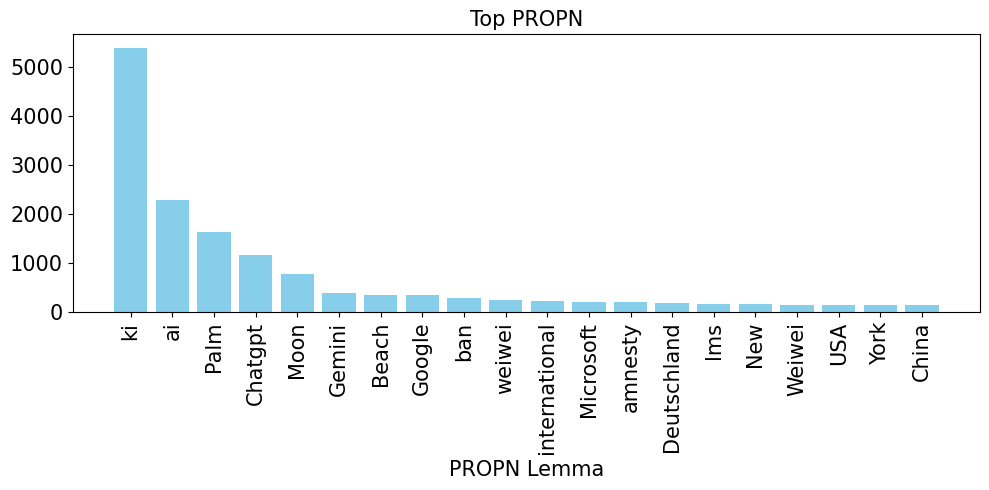

<Figure size 640x480 with 0 Axes>

In [ ]:
# count proper nouns in all sentences
count_POS(all_sents_df['text'], nlp, 'PROPN')

Total NOUNs: 66097
NOUN types:
  Intelligenz: 3156
  Jahr: 653
  Unternehmen: 573
  Copilot: 512
  Mensch: 477
  Ungeneralsekretär: 456
  Einsatz: 376
  Bereich: 371
  Thema: 368
  Chatbot: 363
  Prozent: 355
  copilot: 258
  Technologie: 244
  daten: 240
  Frage: 237
  ban: 227
  Zukunft: 211
  Entwicklung: 200
  Palm: 196
  Million: 183
  Welt: 182
  Beispiel: 170
  Bild: 167
  Anwendung: 166
  Text: 158
  Künstler: 158
  Land: 155
  Nutzer: 153
  Ende: 150
  Zeit: 147
  Problem: 142
  Antwort: 141
  Information: 141
  Euro: 138
  Tag: 137
  Fall: 134
  Firma: 134
  Sprachmodelle: 133
  Möglichkeit: 130
  System: 130
  Dollar: 127
  Modell: 124
  Ergebnis: 120
  Inhalt: 118
  Woche: 117
  Monat: 116
  Rolle: 115
  Leben: 113
  Milliarde: 112
  Studie: 111
  Chance: 111
  Arbeit: 109
  Maschine: 108
  Internet: 108
  Produkt: 106
  Funktion: 104
  Software: 101
  Kunde: 101
  Teil: 101
  Team: 100
  Nutzung: 99
  Ziel: 99
  Hilfe: 99
  Uhr: 98
  Aufgabe: 96
  Weg: 95
  Markt: 95
  Ber

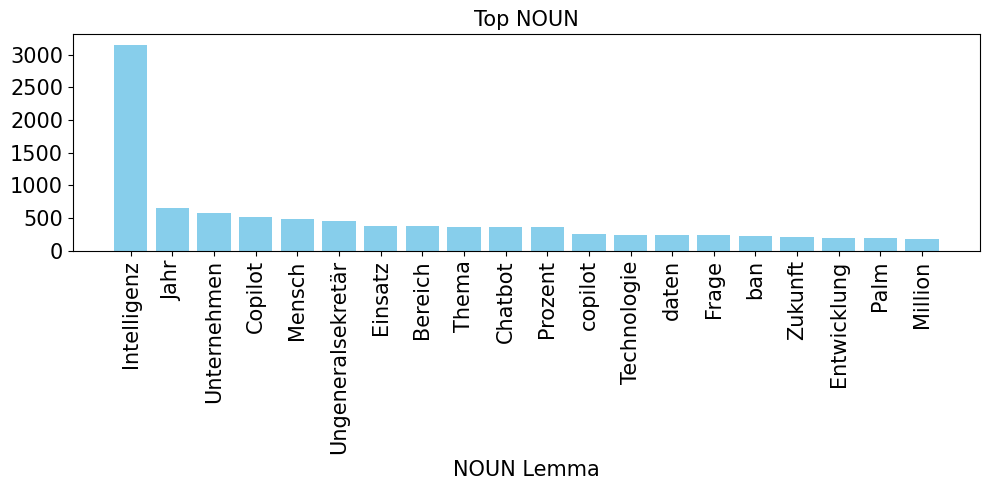

<Figure size 640x480 with 0 Axes>

In [ ]:
# count nouns in all sentences
count_POS(all_sents_df['text'], nlp, 'NOUN')